In [1]:
import sys
sys.path.append("..")

from analysis.utils import get_runs_data, show_config_differences
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style(style="darkgrid")

In [2]:
data = get_runs_data(
    tag="iso-info-test", 
    # project="memorization",
    metrics=[
        "train/exact_match_repeated",
        "train/loss_total_per_bit",
    ]
)
show_config_differences(data)

Found 2 runs with tag 'iso-info-test'


,cfg.dataset.length,cfg.dataset.vocab_size,cfg.dataset.prefix_length,cfg.dataset.suffix_length
_run_id,,,,
jwhm2zpq,100,1024,50,50
o0t2xmr8,250,16,125,125


# Iso Information Experiment

This experiment tests whether memorization rate in transformers depends solely on **information content (bits)** or is affected by **vocabulary size through interference effects**.

### Hypotheses

**Null Hypothesis (Bit-Cost-Only)**: Memorization rate overlaps across different vocabulary sizes with same information content
- Prediction: Transformers treat tokens as arbitrary bit-carrying units
- Expected result: Similar memorization curves when total bits are constant

**Alternative Hypothesis (Interference)**: Small-vocab datasets are memorized more slowly despite identical bit content
- Prediction: Interference requires longer prefixes to disambiguate sequences
- Expected result: Slower memorization for small vocabularies (e.g., V=2) compared to larger vocabularies (e.g., V=256)


Specific setup: 

| V    | log2(V) | Bits/Tok | Length | Prefix | Suffix | Total   |
|------|---------|----------|--------|--------|--------|---------|
| 16   | 4.0     | 4.0000   | 250    | 125    | 125    | 1000.00 |
| 1024 | 10.0    | 10.0000  | 100    | 50     | 50     | 1000.00 |

# TODO: evaluate using same length for prefix 

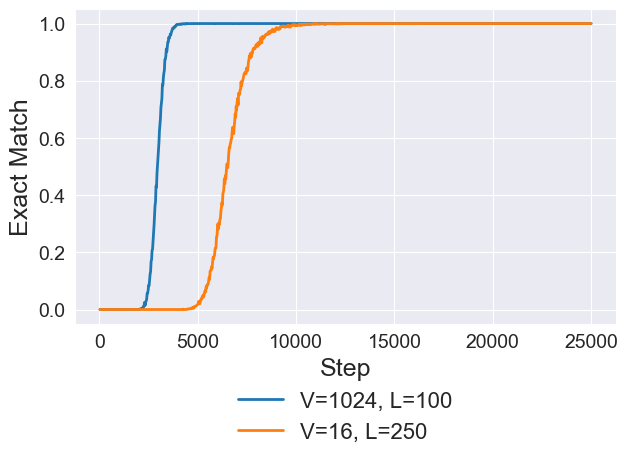

In [3]:
groups = data.groupby(['cfg.dataset.length', 'cfg.dataset.vocab_size'])[["train/exact_match_repeated", "train/global_step"]]
for (length, voc), group in groups:
    steps = group["train/global_step"].to_list()
    exact_match = group["train/exact_match_repeated"].to_list()
    label=f"V={voc}, L={length}"
    plt.plot(steps, exact_match, label=label, linewidth=2)

plt.xlabel('Step', fontsize=18)
plt.ylabel('Exact Match', fontsize=18)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.legend(fontsize=14)
plt.legend(
    loc='upper center', 
    bbox_to_anchor=(0.5, -0.15), 
    fontsize=16, 
    ncol=1,
    frameon=False
)
plt.tight_layout()
plt.show()

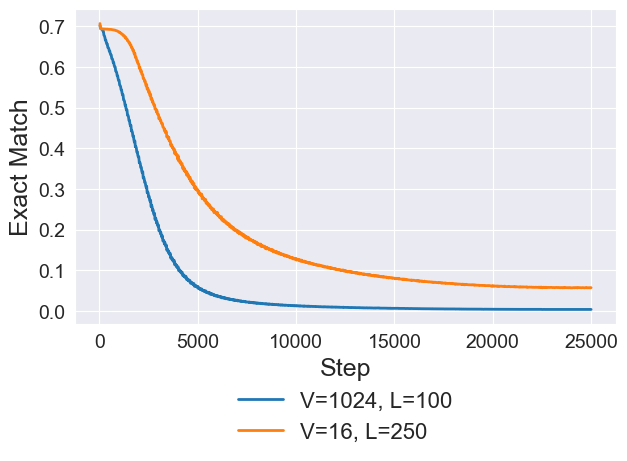

In [4]:
groups = data.groupby(['cfg.dataset.length', 'cfg.dataset.vocab_size'])[["train/loss_total_per_bit", "train/global_step"]]
for (length, voc), group in groups:
    steps = group["train/global_step"].to_list()
    loss_total_per_bit = group["train/loss_total_per_bit"].to_list()
    label=f"V={voc}, L={length}"
    plt.plot(steps, loss_total_per_bit, label=label, linewidth=2)

plt.xlabel('Step', fontsize=18)
plt.ylabel('Exact Match', fontsize=18)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.legend(fontsize=14)
plt.legend(
    loc='upper center', 
    bbox_to_anchor=(0.5, -0.15), 
    fontsize=16, 
    ncol=1,
    frameon=False
)
plt.tight_layout()
plt.show()

# Interference Experiment

This experiment tests whether memorization rate in transformers depends on **disambiguating content in the prefix** versus **overall information content** by creating sequences with two distinct regions (prefix and suffix), each using different vocabulary sizes while maintaining constant total information.

### Research Question

**Is it the disambiguating content (prefix) that matters or the overall information content?**

### Hypotheses

**Hypothesis A (Prefix Matters)**: Dataset with larger prefix vocab (V=256) should memorize faster despite having smaller suffix vocab
- **Reasoning**: Larger prefix vocabulary → fewer prefix collisions → easier disambiguation
- **Key Insight**: More "disambiguating bits" in prefix region enable faster memorization
- **Expected**: Dataset 2 (V_prefix=256) reaches 50%, 75%, 90% exact match faster

**Hypothesis B (Total Information Matters)**: Both datasets should memorize at similar rates
- **Reasoning**: Total information content is constant (iso-information constraint)
- **Key Insight**: Transformers treat all bits equally regardless of sequence position
- **Expected**: Similar memorization curves when plotting against training steps or total_bits_seen

Specific setup:

Prefix Length: 75, Suffix Length: 75

| V_prefix | V_suffix | Prefix Bits | Suffix Bits | Total Bits | Error   |
|----------|----------|-------------|-------------|------------|---------|
| 16       | 645      | 300.00      | 699.99      | 999.99     | 0.0133  |
| 1024     | 10       | 750.00      | 249.14      | 999.14     | 0.8554  |

In [16]:
data = get_runs_data(
    tag="prefix-ambiguity-test", 
    project="memorization",
    metrics=[
        "train/exact_match_repeated",
        "train/loss_total_per_bit",
        "train/loss_total_suffix_per_bit",
        "train/loss_total_prefix_per_bit",
        "train/loss_total_prefix",
        "train/loss_total_suffix",
        "train/loss_total",
    ]
)
show_config_differences(data)

Found 2 runs with tag 'prefix-ambiguity-test'


,cfg.dataset.prefix_vocab_size,cfg.dataset.suffix_vocab_size
_run_id,,
7e6lv9ec,16,645
x1ag54a7,1024,10


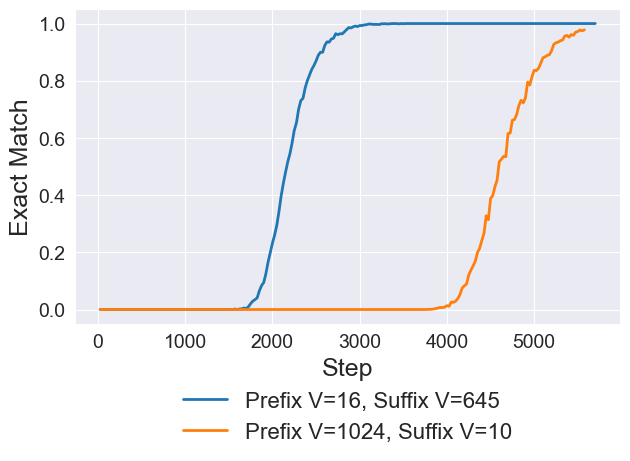

In [6]:
groups = data.groupby(['cfg.dataset.prefix_vocab_size', 'cfg.dataset.suffix_vocab_size'])[["train/exact_match_repeated", "train/global_step"]]
for (prefix_voc, suffix_voc), group in groups:
    steps = group["train/global_step"].to_list()
    exact_match = group["train/exact_match_repeated"].to_list()
    label=f"Prefix V={prefix_voc}, Suffix V={suffix_voc}"
    plt.plot(steps, exact_match, label=label, linewidth=2)

plt.xlabel('Step', fontsize=18)
plt.ylabel('Exact Match', fontsize=18)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.legend(fontsize=14)
plt.legend(
    loc='upper center', 
    bbox_to_anchor=(0.5, -0.15), 
    fontsize=16, 
    ncol=1,
    frameon=False
)
plt.tight_layout()
plt.show()

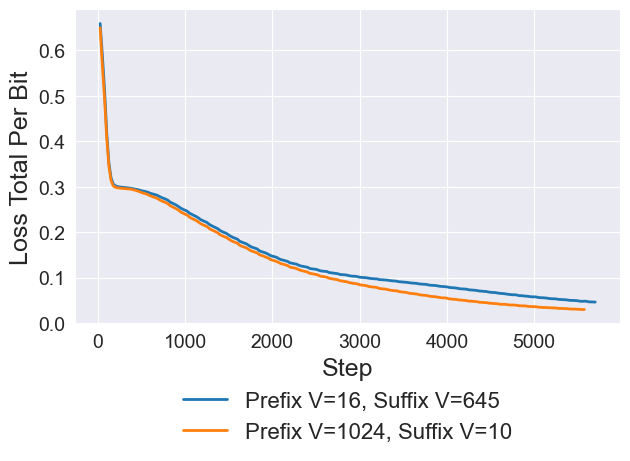

In [7]:
groups = data.groupby(['cfg.dataset.prefix_vocab_size', 'cfg.dataset.suffix_vocab_size'])[["train/loss_total_per_bit", "train/global_step"]]
for (prefix_voc, suffix_voc), group in groups:
    steps = group["train/global_step"].to_list()
    loss_total_per_bit = group["train/loss_total_per_bit"].to_list()
    label=f"Prefix V={prefix_voc}, Suffix V={suffix_voc}"
    plt.plot(steps, loss_total_per_bit, label=label, linewidth=2)

plt.xlabel('Step', fontsize=18)
plt.ylabel('Loss Total Per Bit', fontsize=18)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.legend(fontsize=14)
plt.legend(
    loc='upper center', 
    bbox_to_anchor=(0.5, -0.15), 
    fontsize=16, 
    ncol=1,
    frameon=False
)
plt.tight_layout()
plt.show()

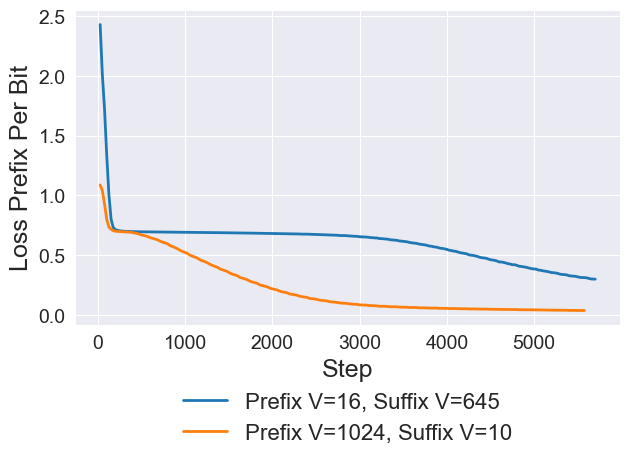

In [8]:
groups = data.groupby(['cfg.dataset.prefix_vocab_size', 'cfg.dataset.suffix_vocab_size'])[["train/loss_total_prefix_per_bit", "train/global_step"]]
for (prefix_voc, suffix_voc), group in groups:
    steps = group["train/global_step"].to_list()
    loss_total_per_bit = group["train/loss_total_prefix_per_bit"].to_list()
    label=f"Prefix V={prefix_voc}, Suffix V={suffix_voc}"
    plt.plot(steps, loss_total_per_bit, label=label, linewidth=2)

plt.xlabel('Step', fontsize=18)
plt.ylabel('Loss Prefix Per Bit', fontsize=18)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.legend(fontsize=14)
plt.legend(
    loc='upper center', 
    bbox_to_anchor=(0.5, -0.15), 
    fontsize=16, 
    ncol=1,
    frameon=False
)
plt.tight_layout()
plt.show()

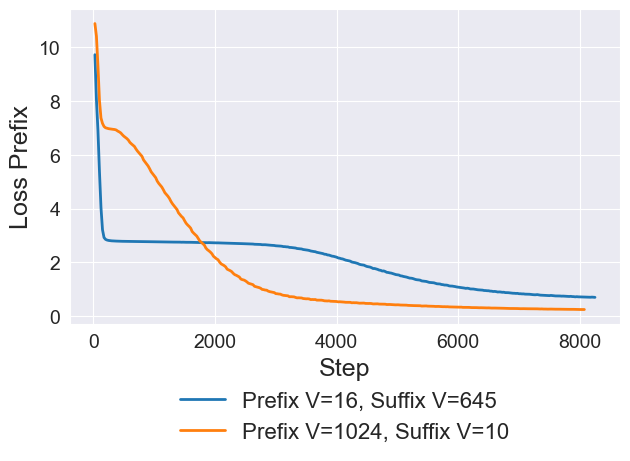

In [14]:
groups = data.groupby(['cfg.dataset.prefix_vocab_size', 'cfg.dataset.suffix_vocab_size'])[["train/loss_total_prefix", "train/global_step"]]
for (prefix_voc, suffix_voc), group in groups:
    steps = group["train/global_step"].to_list()
    loss_total_per_bit = group["train/loss_total_prefix"].to_list()
    label=f"Prefix V={prefix_voc}, Suffix V={suffix_voc}"
    plt.plot(steps, loss_total_per_bit, label=label, linewidth=2)

plt.xlabel('Step', fontsize=18)
plt.ylabel('Loss Prefix', fontsize=18)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.legend(fontsize=14)
plt.legend(
    loc='upper center', 
    bbox_to_anchor=(0.5, -0.15), 
    fontsize=16, 
    ncol=1,
    frameon=False
)
plt.tight_layout()
plt.show()

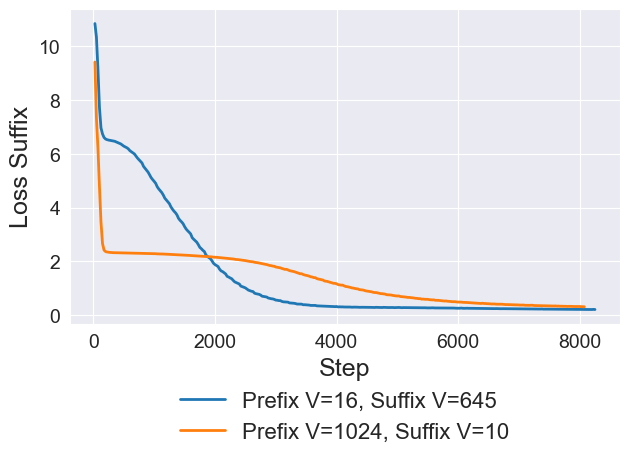

In [15]:
groups = data.groupby(['cfg.dataset.prefix_vocab_size', 'cfg.dataset.suffix_vocab_size'])[["train/loss_total_suffix", "train/global_step"]]
for (prefix_voc, suffix_voc), group in groups:
    steps = group["train/global_step"].to_list()
    loss_total_per_bit = group["train/loss_total_suffix"].to_list()
    label=f"Prefix V={prefix_voc}, Suffix V={suffix_voc}"
    plt.plot(steps, loss_total_per_bit, label=label, linewidth=2)

plt.xlabel('Step', fontsize=18)
plt.ylabel('Loss Suffix', fontsize=18)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.legend(fontsize=14)
plt.legend(
    loc='upper center', 
    bbox_to_anchor=(0.5, -0.15), 
    fontsize=16, 
    ncol=1,
    frameon=False
)
plt.tight_layout()
plt.show()

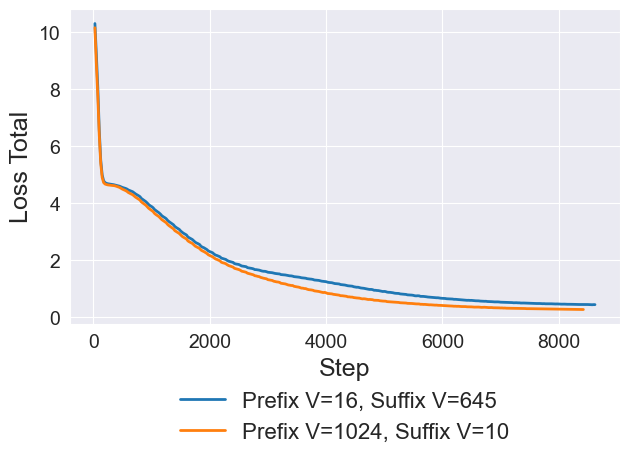

In [17]:
groups = data.groupby(['cfg.dataset.prefix_vocab_size', 'cfg.dataset.suffix_vocab_size'])[["train/loss_total", "train/global_step"]]
for (prefix_voc, suffix_voc), group in groups:
    steps = group["train/global_step"].to_list()
    loss_total_per_bit = group["train/loss_total"].to_list()
    label=f"Prefix V={prefix_voc}, Suffix V={suffix_voc}"
    plt.plot(steps, loss_total_per_bit, label=label, linewidth=2)

plt.xlabel('Step', fontsize=18)
plt.ylabel('Loss Total', fontsize=18)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.legend(fontsize=14)
plt.legend(
    loc='upper center', 
    bbox_to_anchor=(0.5, -0.15), 
    fontsize=16, 
    ncol=1,
    frameon=False
)
plt.tight_layout()
plt.show()

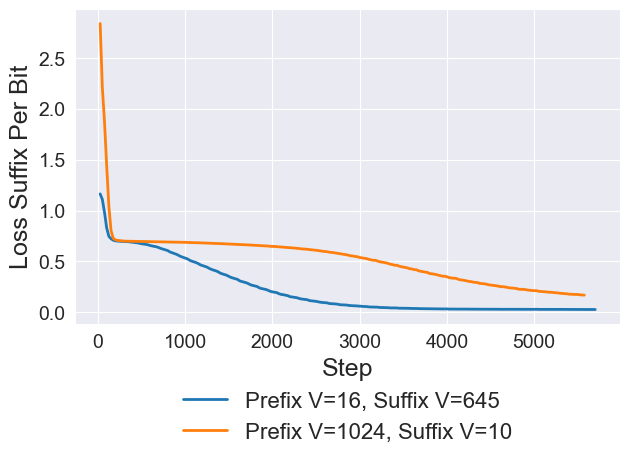

In [9]:
groups = data.groupby(['cfg.dataset.prefix_vocab_size', 'cfg.dataset.suffix_vocab_size'])[["train/loss_total_suffix_per_bit", "train/global_step"]]
for (prefix_voc, suffix_voc), group in groups:
    steps = group["train/global_step"].to_list()
    loss_total_per_bit = group["train/loss_total_suffix_per_bit"].to_list()
    label=f"Prefix V={prefix_voc}, Suffix V={suffix_voc}"
    plt.plot(steps, loss_total_per_bit, label=label, linewidth=2)

plt.xlabel('Step', fontsize=18)
plt.ylabel('Loss Suffix Per Bit', fontsize=18)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.legend(fontsize=14)
plt.legend(
    loc='upper center', 
    bbox_to_anchor=(0.5, -0.15), 
    fontsize=16, 
    ncol=1,
    frameon=False
)
plt.tight_layout()
plt.show()